# Traffic Crash Models

Two studies, two datasets:

- `features.xls`
- `traffic_case_study.xlsx`

### Note: Claude Opus 5.5 was used as an assistant  

## Load the raw data

In [1]:
import pandas as pd

In [2]:
features = pd.read_excel("features.xls")
features.shape

(1030, 80)

In [3]:
features.head()

,AUTOMOBILE_COUNT,BUS_COUNT,COLLISION_TYPE,COUNTY,CRASH_MONTH,DAY_OF_WEEK,DRIVER_COUNT_16YR,DRIVER_COUNT_17YR,DRIVER_COUNT_18YR,DRIVER_COUNT_19YR,...,SPEEDING,STATE_ROAD,STOP_CONTROLLED_INT,SUDDEN_DEER,VULNERABLE_ROAD_USER,WET_ROAD,WORK_ZONE,YOUNG_DRIVER,LANE_COUNT,SPEED_LIMIT
0,1.0,0.0,2.0,2.0,5.0,4.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,25.0
1,1.0,0.0,2.0,2.0,5.0,4.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4.0,35.0
2,0.0,0.0,7.0,31.0,6.0,5.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,NaN,NaN,0.0,1.0,2.0,25.0
3,0.0,0.0,7.0,23.0,5.0,5.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,NaN,0.0,0.0,0.0,2.0,35.0
4,3.0,0.0,2.0,2.0,6.0,4.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,NaN,0.0,NaN,2.0,35.0


In [4]:
case_study = pd.read_excel("traffic_case_study.xlsx")
case_study.shape

(600, 26)

In [5]:
case_study.head()

,AUTOMOBILE_COUNT,SPEED_LIMIT,URBAN_RURAL,URBAN,YOUNG_DRIVER,COLLISION_TYPE,LANE_COUNT,BICYCLE_COUNT,BUS_COUNT,ILLUMINATION,...,DRUGGED_DRIVER,FATAL_OR_SUSP_SERIOUS_INJ,FATIGUE_ASLEEP,HIT_FIXED_OBJECT,LANE_DEPARTURE,MATURE_DRIVER,OVERTURNED,SCHOOL_ZONE,SPEEDING_RELATED,WET_ROAD
0,1,25.0,4,1.0,0.0,2,2.0,1,0.0,1,...,0,0,0,0,0,0,0,0,0,0
1,1,35.0,4,1.0,0.0,2,4.0,1,0.0,1,...,0,0,0,0,0,0,0,0,0,0
2,0,25.0,1,0.0,1.0,7,2.0,0,0.0,1,...,0,0,0,1,1,0,0,0,0,0
3,0,35.0,4,1.0,0.0,7,2.0,0,0.0,1,...,1,0,0,1,1,0,0,0,1,0
4,3,35.0,4,1.0,0.0,2,2.0,0,0.0,1,...,0,0,0,0,1,1,0,0,0,0


## Features data: missing values

In [6]:
nulls = features.isnull().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)
print(len(nulls), "of", features.shape[1], "fields have null values\n")
print(nulls.to_string())

80 of 80 fields have null values

STOP_CONTROLLED_INT          264
DRIVER_50_64YR               264
DRIVER_20YR                  264
ILLUMINATION                 264
DAY_OF_WEEK                  263
CELL_PHONE                   240
SECONDARY_CRASH              237
CRASH_MONTH                  237
TIME_OF_DAY                  230
YOUNG_DRIVER                 230
SIGNALIZED_INT               228
VULNERABLE_ROAD_USER         225
BICYCLE                      223
WET_ROAD                     214
MOTORCYCLE                   213
MULTIPLE_VEHICLE             204
HOUR_OF_DAY                   30
HEAVY_TRUCK_COUNT             30
DRIVER_COUNT_75PLUS           30
DRIVER_COUNT_65_74YR          30
DRIVER_COUNT_50_64YR          30
DRIVER_COUNT_20YR             30
DRIVER_COUNT_19YR             30
DRIVER_COUNT_18YR             30
DRIVER_COUNT_17YR             30
DRIVER_COUNT_16YR             30
COLLISION_TYPE                30
COUNTY                        30
BUS_COUNT                     30
AUTOMOBIL

## Data Cleaning 

Got rid of rows 1000–1029 as theses were completly useless 

In [7]:
features = features.dropna(subset=["FATAL_OR_SUSP_SERIOUS_INJ"]).reset_index(drop=True)
features.shape

(1000, 80)

In [8]:
nulls = features.isnull().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)
print(len(nulls), "of", features.shape[1], "fields have null values\n")
print(nulls.to_string())

16 of 80 fields have null values

ILLUMINATION            234
DRIVER_20YR             234
STOP_CONTROLLED_INT     234
DRIVER_50_64YR          234
DAY_OF_WEEK             233
CELL_PHONE              210
SECONDARY_CRASH         207
CRASH_MONTH             207
MOTORCYCLE              206
MULTIPLE_VEHICLE        201
YOUNG_DRIVER            200
TIME_OF_DAY             200
SIGNALIZED_INT          198
VULNERABLE_ROAD_USER    195
BICYCLE                 193
WET_ROAD                184


## Handling the missing values

| Field | Method |
|---|---|
| `CRASH_MONTH` | Dropped |
| `DAY_OF_WEEK` | Dropped |
| `TIME_OF_DAY` | Dropped (`HOUR_OF_DAY` has the same hour) |
| `ILLUMINATION` | Dropped (`ILLUMINATION_DARK` has dark / not dark) |
| `WET_ROAD` | Filled from `ROAD_CONDITION`: 08 (water) or 09 (wet) = 1 |
| `YOUNG_DRIVER` | Filled from driver counts: any driver aged 16–20 = 1 |
| `DRIVER_20YR` | Filled from `DRIVER_COUNT_20YR` > 0 |
| `DRIVER_50_64YR` | Filled from `DRIVER_COUNT_50_64YR` > 0 |
| `MULTIPLE_VEHICLE` | Filled from `VEHICLE_COUNT` ≥ 2 |
| `CELL_PHONE` | Not distracted = 0; remaining gaps: mean of distracted crashes |
| `SIGNALIZED_INT` | Not at an intersection = 0; remaining gaps: mean of intersection crashes |
| `STOP_CONTROLLED_INT` | Not at an intersection = 0; remaining gaps: mean of intersection crashes, plus a `STOP_CONTROLLED_INT_MISSING` flag |
| `VULNERABLE_ROAD_USER` | Pedestrian or bicycle involved = 1, neither = 0; remaining gaps: mean |
| `BICYCLE` | No vulnerable road user = 0; vulnerable road user but no pedestrian = 1; remaining gaps: mean |
| `MOTORCYCLE` | Mean, plus a `MOTORCYCLE_MISSING` flag |
| `SECONDARY_CRASH` | Mean |

In [9]:
df = features.copy()

# Dropped fields
df = df.drop(columns=["CRASH_MONTH", "DAY_OF_WEEK", "TIME_OF_DAY", "ILLUMINATION"])

# Filled from other columns
young_counts = ["DRIVER_COUNT_16YR", "DRIVER_COUNT_17YR", "DRIVER_COUNT_18YR", "DRIVER_COUNT_19YR", "DRIVER_COUNT_20YR"]
df["WET_ROAD"] = df["WET_ROAD"].fillna(df["ROAD_CONDITION"].isin([8, 9]).astype(float))
df["YOUNG_DRIVER"] = df["YOUNG_DRIVER"].fillna((df[young_counts].sum(axis=1) > 0).astype(float))
df["DRIVER_20YR"] = df["DRIVER_20YR"].fillna((df["DRIVER_COUNT_20YR"] > 0).astype(float))
df["DRIVER_50_64YR"] = df["DRIVER_50_64YR"].fillna((df["DRIVER_COUNT_50_64YR"] > 0).astype(float))
df["MULTIPLE_VEHICLE"] = df["MULTIPLE_VEHICLE"].fillna((df["VEHICLE_COUNT"] >= 2).astype(float))

In [10]:
# Partly filled from other columns, remaining gaps filled with a mean

# CELL_PHONE
cell_mean = df.loc[df["DISTRACTED"] == 1, "CELL_PHONE"].mean()
df.loc[df["CELL_PHONE"].isna() & (df["DISTRACTED"] == 0), "CELL_PHONE"] = 0
df["CELL_PHONE"] = df["CELL_PHONE"].fillna(cell_mean)

# SIGNALIZED_INT
signal_mean = df.loc[df["INTERSECTION"] == 1, "SIGNALIZED_INT"].mean()
df.loc[df["SIGNALIZED_INT"].isna() & (df["INTERSECTION"] == 0), "SIGNALIZED_INT"] = 0
df["SIGNALIZED_INT"] = df["SIGNALIZED_INT"].fillna(signal_mean)

# STOP_CONTROLLED_INT (with a flag for the mean-filled rows)
stop_mean = df.loc[df["INTERSECTION"] == 1, "STOP_CONTROLLED_INT"].mean()
df.loc[df["STOP_CONTROLLED_INT"].isna() & (df["INTERSECTION"] == 0), "STOP_CONTROLLED_INT"] = 0
df["STOP_CONTROLLED_INT_MISSING"] = df["STOP_CONTROLLED_INT"].isna().astype(int)
df["STOP_CONTROLLED_INT"] = df["STOP_CONTROLLED_INT"].fillna(stop_mean)

# VULNERABLE_ROAD_USER and BICYCLE (each helps fill the other, using the original values)
vru, bike = df["VULNERABLE_ROAD_USER"].copy(), df["BICYCLE"].copy()
vru_mean, bike_mean = vru.mean(), bike.mean()

df.loc[vru.isna() & (df["PED_COUNT"] > 0), "VULNERABLE_ROAD_USER"] = 1
df.loc[vru.isna() & (df["PED_COUNT"] == 0) & bike.notna(), "VULNERABLE_ROAD_USER"] = bike
df.loc[bike.isna() & (vru == 0), "BICYCLE"] = 0
df.loc[bike.isna() & (vru == 1) & (df["PED_COUNT"] == 0), "BICYCLE"] = 1

df["VULNERABLE_ROAD_USER"] = df["VULNERABLE_ROAD_USER"].fillna(vru_mean)
df["BICYCLE"] = df["BICYCLE"].fillna(bike_mean)

In [11]:
# Mean only

df["MOTORCYCLE_MISSING"] = df["MOTORCYCLE"].isna().astype(int)
df["MOTORCYCLE"] = df["MOTORCYCLE"].fillna(df["MOTORCYCLE"].mean())
df["SECONDARY_CRASH"] = df["SECONDARY_CRASH"].fillna(df["SECONDARY_CRASH"].mean())

In [12]:
print("Missing values left:", df.isnull().sum().sum())
df.shape

Missing values left: 0


(1000, 78)

## Feature selection

### Step 1: Prepare the features

- Leave out the outcome `FATAL_OR_SUSP_SERIOUS_INJ`
- Drop `COUNTY`, `URBAN_AREA` (codes, not amounts), `URBAN_RURAL` (same as `RURAL`) and `ROAD_CONDITION` (same as the road-surface flags)
- Split `COLLISION_TYPE` into one yes/no column per collision type

In [13]:
TARGET = "FATAL_OR_SUSP_SERIOUS_INJ"
collision_names = {0: "NON_COLLISION", 1: "REAR_END", 2: "HEAD_ON", 3: "BACKING", 4: "ANGLE",
                   5: "SIDESWIPE_SAME_DIR", 6: "SIDESWIPE_OPP_DIR", 7: "HIT_FIXED_OBJECT",
                   8: "HIT_NON_MOTORIST", 98: "OTHER"}

y = df[TARGET]
X = df.drop(columns=[TARGET, "COUNTY", "URBAN_AREA", "URBAN_RURAL", "ROAD_CONDITION", "COLLISION_TYPE"])
X = X.join(pd.get_dummies(df["COLLISION_TYPE"].map(collision_names), prefix="COLL").astype(int))
X.shape

(1000, 81)

### Step 2: Multicollinearity check

- Yes/no pair: chi-square test, strength = Cramér's V
- Pair with a count or number: Pearson's r
- Strength above 0.8: drop one of the pair · 0.7–0.8: marginal (keep both for now) · below 0.7: keep both

In [14]:
from itertools import combinations
import numpy as np
from scipy.stats import chi2_contingency, pearsonr

def association_pairs(X):
    yes_no = [c for c in X if X[c].between(0, 1).all()]
    rows = []
    for a, b in combinations(X.columns, 2):
        if a in yes_no and b in yes_no:
            both = X[a].isin([0, 1]) & X[b].isin([0, 1])          # skip mean-imputed values
            table = pd.crosstab(X.loc[both, a], X.loc[both, b])
            chi2, p, _, _ = chi2_contingency(table, correction=False)
            strength, test = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))), "Cramér's V"
        else:
            r, p = pearsonr(X[a], X[b])
            strength, test = abs(r), "Pearson |r|"
        rows.append({"Feature A": a, "Feature B": b, "Test": test, "Strength": strength, "p-value": p})
    return pd.DataFrame(rows).sort_values("Strength", ascending=False).reset_index(drop=True)

# The two "was missing" flags belong to their feature, so they are left out of the check
pairs = association_pairs(X.drop(columns=["MOTORCYCLE_MISSING", "STOP_CONTROLLED_INT_MISSING"]))
print(len(pairs), "pairs tested |", (pairs["Strength"] > 0.8).sum(), "above 0.8 |",
      pairs["Strength"].between(0.7, 0.8).sum(), "marginal (0.7–0.8)")

3081 pairs tested | 27 above 0.8 | 4 marginal (0.7–0.8)


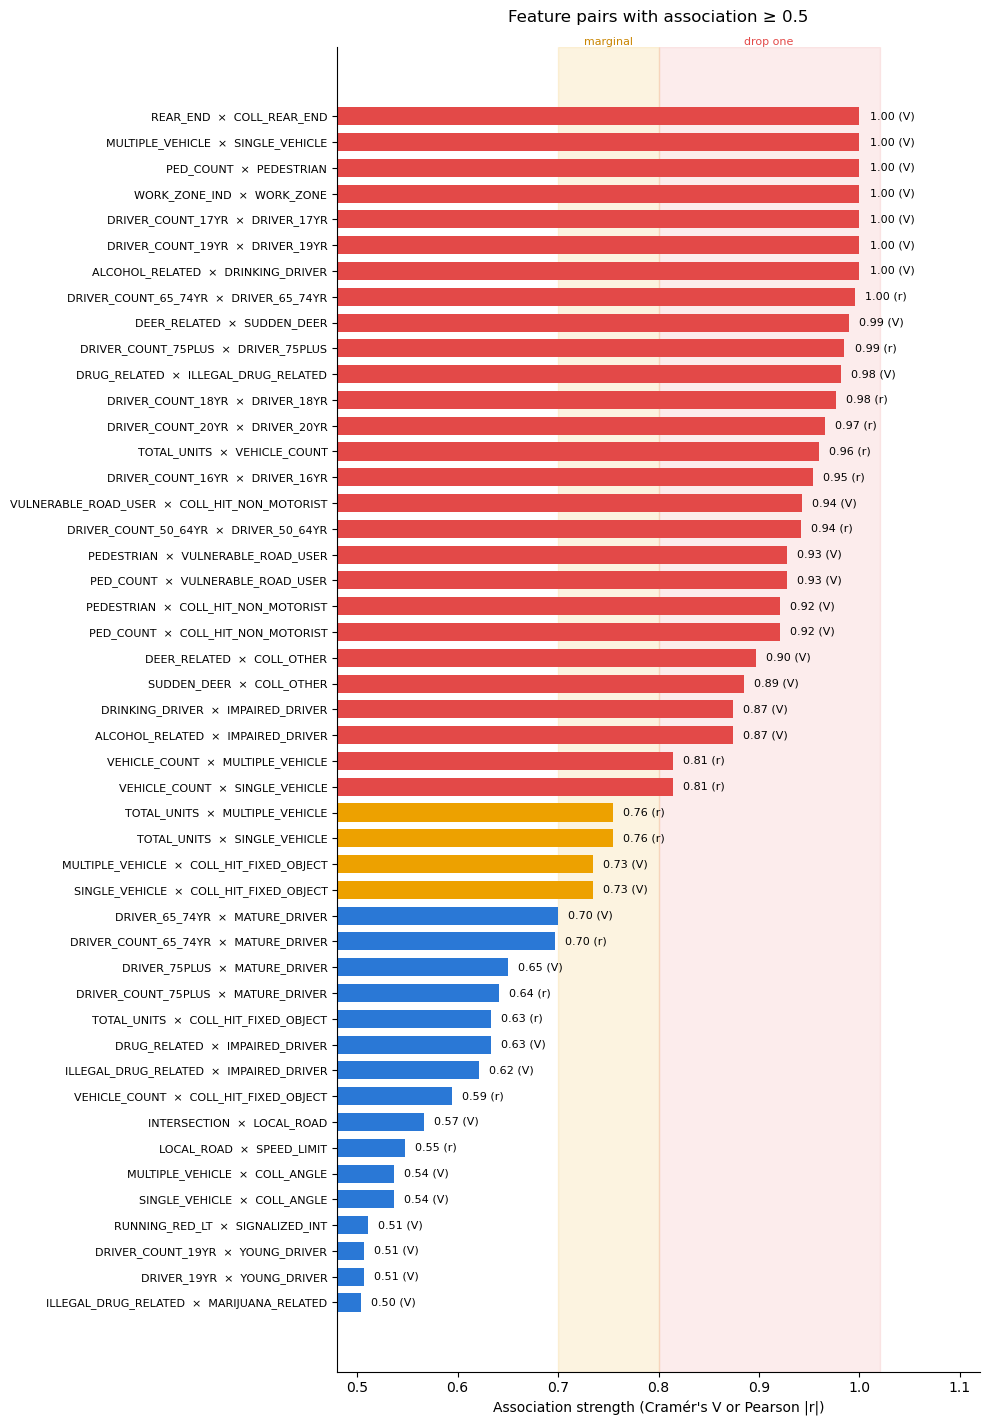

In [15]:
import matplotlib.pyplot as plt

def plot_pairs(pairs, title, min_strength=0.5):
    top = pairs[pairs["Strength"] >= min_strength].iloc[::-1]
    colors = ["#e34948" if s > 0.8 else "#eda100" if s >= 0.7 else "#2a78d6" for s in top["Strength"]]
    fig, ax = plt.subplots(figsize=(10, 0.28 * len(top) + 1.2))
    ax.axvspan(0.7, 0.8, color="#eda100", alpha=0.12)
    ax.axvspan(0.8, 1.02, color="#e34948", alpha=0.10)
    ax.barh(top["Feature A"] + "  ×  " + top["Feature B"], top["Strength"], color=colors, height=0.7)
    for i, (s, t) in enumerate(zip(top["Strength"], top["Test"])):
        ax.text(s + 0.01, i, f"{s:.2f} ({'V' if t.startswith('Cram') else 'r'})", va="center", fontsize=8)
    ax.set_xlim(min_strength - 0.02, 1.12)
    ax.set_xlabel("Association strength (Cramér's V or Pearson |r|)")
    ax.set_title(title, pad=18)
    ax.text(0.75, 1.0, "marginal", ha="center", va="bottom", fontsize=8, color="#c98500", transform=ax.get_xaxis_transform())
    ax.text(0.91, 1.0, "drop one", ha="center", va="bottom", fontsize=8, color="#e34948", transform=ax.get_xaxis_transform())
    ax.tick_params(axis="y", labelsize=8)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    plt.tight_layout()
    plt.show()

plot_pairs(pairs, "Feature pairs with association ≥ 0.5")

**Pairs above 0.8: which one is dropped.** Rule: keep the broader or clearer column.

| Dropped | Kept | Reason |
|---|---|---|
| `DRIVER_COUNT_16YR` … `DRIVER_COUNT_75PLUS` (8) | `DRIVER_16YR` … `DRIVER_75PLUS` | Yes/no flag kept over its count |
| `ALCOHOL_RELATED`, `DRINKING_DRIVER` | `IMPAIRED_DRIVER` | Broader (alcohol or drugs) |
| `ILLEGAL_DRUG_RELATED` | `DRUG_RELATED` | Broader |
| `PEDESTRIAN`, `PED_COUNT`, `COLL_HIT_NON_MOTORIST` | `VULNERABLE_ROAD_USER` | Broader (pedestrian or bicycle) |
| `MULTIPLE_VEHICLE`, `VEHICLE_COUNT` | `SINGLE_VEHICLE` | Opposite / count of the same thing |
| `SUDDEN_DEER`, `COLL_OTHER` | `DEER_RELATED` | Broader; "other" is not defined |
| `COLL_REAR_END` | `REAR_END` | Identical |
| `WORK_ZONE_IND` | `WORK_ZONE` | Identical |

In [16]:
to_drop = ["DRIVER_COUNT_16YR", "DRIVER_COUNT_17YR", "DRIVER_COUNT_18YR", "DRIVER_COUNT_19YR",
           "DRIVER_COUNT_20YR", "DRIVER_COUNT_50_64YR", "DRIVER_COUNT_65_74YR", "DRIVER_COUNT_75PLUS",
           "ALCOHOL_RELATED", "DRINKING_DRIVER", "ILLEGAL_DRUG_RELATED",
           "PEDESTRIAN", "PED_COUNT", "COLL_HIT_NON_MOTORIST",
           "MULTIPLE_VEHICLE", "VEHICLE_COUNT", "SUDDEN_DEER", "COLL_OTHER", "COLL_REAR_END", "WORK_ZONE_IND"]
X = X.drop(columns=to_drop)

pairs_after = association_pairs(X.drop(columns=["MOTORCYCLE_MISSING", "STOP_CONTROLLED_INT_MISSING"]))
print(X.shape[1], "features left | strongest remaining pair:", round(pairs_after["Strength"].max(), 2))
pairs_after[pairs_after["Strength"] >= 0.7]

61 features left | strongest remaining pair: 0.76


,Feature A,Feature B,Test,Strength,p-value
0,TOTAL_UNITS,SINGLE_VEHICLE,Pearson |r|,0.755077,3.575111e-185
1,SINGLE_VEHICLE,COLL_HIT_FIXED_OBJECT,Cramér's V,0.734979,1.711010e-119


### Step 3: SelectKBest (chi-square)

- Score every feature by its chi-square association with `FATAL_OR_SUSP_SERIOUS_INJ` and keep the top 10
- The two "was missing" flags are left out
- Chi-square says how strongly a feature is linked to the outcome, not in which direction, so the severe rate when the feature = yes is shown next to it (overall rate: 5.1%)

In [17]:
from sklearn.feature_selection import SelectKBest, chi2

X_kbest = X.drop(columns=["MOTORCYCLE_MISSING", "STOP_CONTROLLED_INT_MISSING"])
selector = SelectKBest(chi2, k=10).fit(X_kbest, y)

ranking = pd.DataFrame({
    "Chi-square": selector.scores_,
    "p-value": selector.pvalues_,
    "Severe rate when yes": [y[X_kbest[c] == 1].mean() if X_kbest[c].between(0, 1).all() else np.nan for c in X_kbest],   # yes/no features only
}, index=X_kbest.columns).sort_values("Chi-square", ascending=False)
ranking["Selected"] = ranking.index.isin(X_kbest.columns[selector.get_support()])

top10 = ranking.index[ranking["Selected"]].tolist()
ranking.head(20).style.format({"Chi-square": "{:.2f}", "p-value": "{:.4f}", "Severe rate when yes": "{:.1%}"}, na_rep="–")

,Chi-square,p-value,Severe rate when yes,Selected
MOTORCYCLE,18.86,0.0000,25.9%,True
IMPAIRED_DRIVER,9.61,0.0019,13.4%,True
REAR_END,9.51,0.0020,0.0%,True
SPEEDING,7.32,0.0068,15.6%,True
DRIVER_75PLUS,7.19,0.0073,11.0%,True
LEFT_TURN,6.64,0.0100,9.3%,True
RUNNING_RED_LT,5.82,0.0158,12.1%,True
DISTRACTED,5.54,0.0186,0.0%,True
RUNNING_STOP_SIGN,4.80,0.0284,12.8%,True
FATIGUE_ASLEEP,4.05,0.0442,15.0%,True


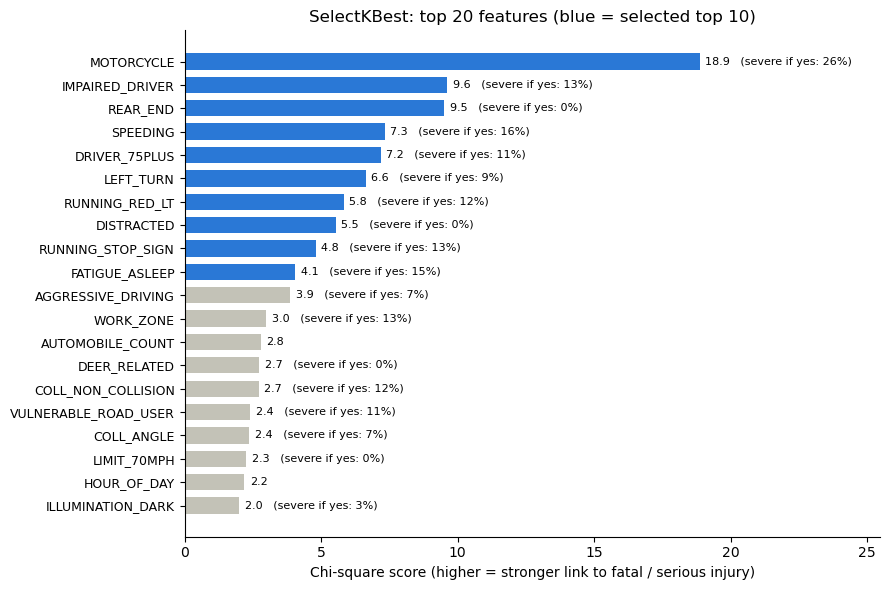

In [18]:
top = ranking.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["Chi-square"], color=["#2a78d6" if s else "#c3c2b7" for s in top["Selected"]], height=0.7)
for i, (score, rate) in enumerate(zip(top["Chi-square"], top["Severe rate when yes"])):
    ax.text(score + 0.2, i, f"{score:.1f}   (severe if yes: {rate:.0%})" if pd.notna(rate) else f"{score:.1f}", va="center", fontsize=8)
ax.set_xlabel("Chi-square score (higher = stronger link to fatal / serious injury)")
ax.set_title("SelectKBest: top 20 features (blue = selected top 10)")
ax.set_xlim(0, top["Chi-square"].max() * 1.35)
ax.tick_params(axis="y", labelsize=9)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## Model

- Features: the top 10 from SelectKBest
- Logistic regression with an L2 penalty (`C = 1.0`); features are standardized first
- Class imbalance handled with `class_weight="balanced"`
- 5-fold stratified cross-validation, repeated 10 times (50 test folds)

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
CLASS_LABELS = ["Not severe", "Fatal / serious injury"]
CLASS_COLORS = ["#a9a8a2", "#e34948"]

### Remove complete duplicates

30 rows are exact copies of another row and are dropped before modeling. (Dropping them before feature selection gives the same top 10.)

In [20]:
keep = ~df.duplicated()
X_model = X.loc[keep, top10]
y_model = y[keep]
print(f"Dropped {(~keep).sum()} duplicate rows → {len(y_model)} rows, {int(y_model.sum())} fatal / serious")

Dropped 30 duplicate rows → 970 rows, 50 fatal / serious


### Class imbalance

Few crashes are severe, so an unweighted model would predict "not severe" for everyone. Balanced class weights give each severe crash more weight, so both classes count equally in training.

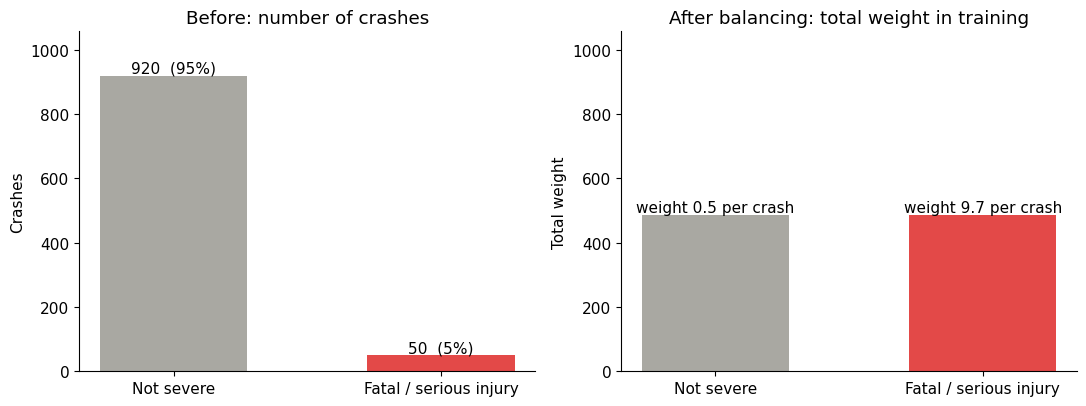

In [21]:
counts = y_model.value_counts().sort_index()
weight_per_crash = len(y_model) / (2 * counts)          # what class_weight="balanced" uses

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bars = axes[0].bar(CLASS_LABELS, counts, color=CLASS_COLORS, width=0.55)
for bar, n in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width() / 2, n, f"{n}  ({n / len(y_model):.0%})", ha="center", va="bottom")
axes[0].set_title("Before: number of crashes")
axes[0].set_ylabel("Crashes")

bars = axes[1].bar(CLASS_LABELS, counts * weight_per_crash, color=CLASS_COLORS, width=0.55)
for bar, w in zip(bars, weight_per_crash):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"weight {w:.1f} per crash", ha="center", va="bottom")
axes[1].set_title("After balancing: total weight in training")
axes[1].set_ylabel("Total weight")
for ax in axes:
    ax.set_ylim(0, max(counts) * 1.15)
plt.tight_layout()
plt.show()

### Cross-validated results

In [22]:
model = make_pipeline(StandardScaler(),
                      LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000))   # L2 penalty is the default
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scores = cross_validate(model, X_model, y_model, cv=cv,
                        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])

metric_names = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1", "roc_auc": "ROC AUC"}
results = pd.DataFrame({"Mean": [scores[f"test_{m}"].mean() for m in metric_names],
                        "Std": [scores[f"test_{m}"].std() for m in metric_names]},
                       index=metric_names.values()).round(3)
results

,Mean,Std
Accuracy,0.711,0.049
Precision,0.107,0.023
Recall,0.618,0.126
F1,0.182,0.036
ROC AUC,0.745,0.058


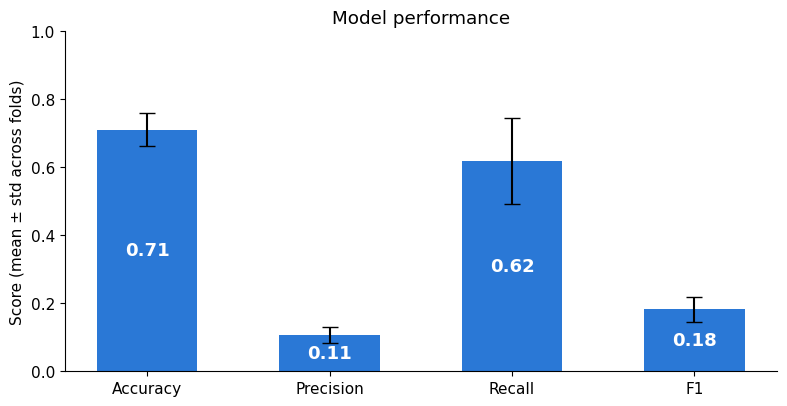

In [23]:
main = results.loc[["Accuracy", "Precision", "Recall", "F1"]]
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(main.index, main["Mean"], yerr=main["Std"], capsize=6, color="#2a78d6", width=0.55)
for bar, v in zip(bars, main["Mean"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v / 2, f"{v:.2f}", ha="center", va="center",
            color="white", fontsize=13, fontweight="bold")
ax.set_ylim(0, 1)
ax.set_ylabel("Score (mean ± std across folds)")
ax.set_title("Model performance")
plt.tight_layout()
plt.show()

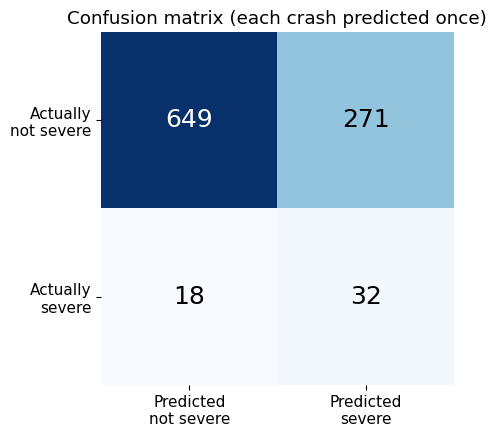

In [24]:
pred = cross_val_predict(model, X_model, y_model, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
cm = confusion_matrix(y_model, pred)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", fontsize=18, color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["Predicted\nnot severe", "Predicted\nsevere"])
ax.set_yticks([0, 1], ["Actually\nnot severe", "Actually\nsevere"])
ax.set_title("Confusion matrix (each crash predicted once)")
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

### Feature importance

Coefficients of the model fitted on all rows. Features are standardized, so the bar lengths are comparable: red raises the risk of a fatal / serious injury, blue lowers it.

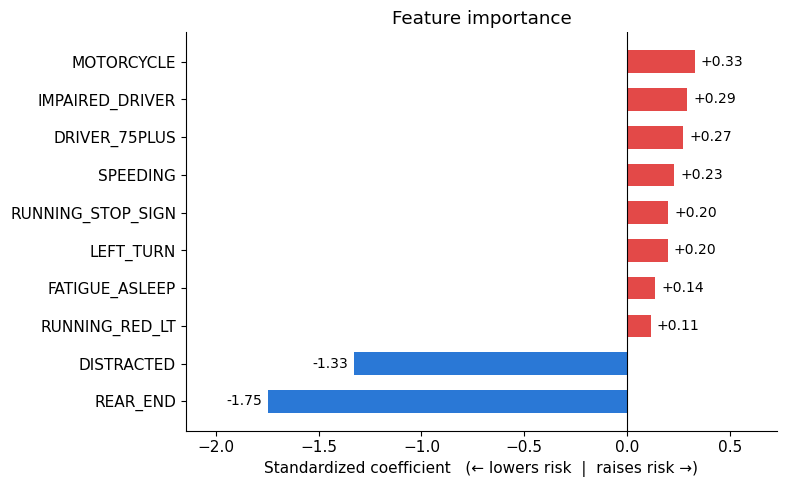

In [25]:
model.fit(X_model, y_model)
coef = pd.Series(model[-1].coef_[0], index=X_model.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coef.index, coef, color=["#e34948" if c > 0 else "#2a78d6" for c in coef], height=0.6)
for i, c in enumerate(coef):
    ax.text(c + (0.03 if c > 0 else -0.03), i, f"{c:+.2f}", va="center", ha="left" if c > 0 else "right", fontsize=10)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(coef.min() - 0.4, coef.max() + 0.4)
ax.set_xlabel("Standardized coefficient   (← lowers risk  |  raises risk →)")
ax.set_title("Feature importance")
plt.tight_layout()
plt.show()

### VIF check

VIF above 5 would signal multicollinearity.

In [26]:
X_const = sm.add_constant(X_model.astype(float))
vif = pd.DataFrame({"VIF": [variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])]},
                   index=X_model.columns).round(2).sort_values("VIF", ascending=False)
vif

,VIF
REAR_END,1.12
LEFT_TURN,1.07
DISTRACTED,1.06
RUNNING_RED_LT,1.04
RUNNING_STOP_SIGN,1.03
SPEEDING,1.03
DRIVER_75PLUS,1.02
IMPAIRED_DRIVER,1.02
MOTORCYCLE,1.01
FATIGUE_ASLEEP,1.01


## Results

**Features (10):** MOTORCYCLE, IMPAIRED_DRIVER, REAR_END, SPEEDING, DRIVER_75PLUS, LEFT_TURN, RUNNING_RED_LT, DISTRACTED, RUNNING_STOP_SIGN, FATIGUE_ASLEEP

| Accuracy | Precision | Recall | F1 |
|---|---|---|---|
| 0.71 | 0.11 | 0.62 | 0.18 |

- The model catches 62% of fatal / serious crashes, but most of its "severe" flags are false alarms (low precision)
- Strongest risk factors: motorcycle, impaired driver, driver 75+, speeding. Rear-end and distracted-driving crashes were never severe
- All VIFs ≈ 1: no multicollinearity